# Classification - Separation problem

## Problem description
There two sets of points $\{x_1,\dots,x_N\}$ and $\{y_1,\dots,y_M\}$. We would like to find a function, $f$, such that 

$f(x_i) > 0, \quad \forall i = 1,\dots,N$

$f(y_i) < 0, \quad \forall i = 1,\dots,M$

## Required packages

In [1]:
import random
import numpy as np
import gurobipy as gp
import matplotlib.pyplot as plt

## Data generation

The following function generates two random sets of data. The number of points and the overlap of the two sets can be controlled.

In [2]:
# Generating points on unit square, separating around y = x
def data_generation(
        number_of_points,
        maximum_overlap,
        minimum_spacing = 0,
        seed = 2026,
    ):
    random.seed(seed)
    X = []
    Y = []
    minimum_spacing = min(minimum_spacing,1)
    for i in range(number_of_points):
        # Generate point
        while True:
            point = (random.random(), random.random())
            closest_point = (point[0]+point[1])/2
            distance = np.linalg.norm(tuple([point[i] - closest_point for i in range(2)]))
            # Check spacing if fine
            if distance > minimum_spacing/2: 
                # Probability of not going in expected set
                prob = 0
                if distance <= maximum_overlap:
                    prob = (1 - distance/maximum_overlap)*0.5
                break
        # Deciding if it switches set or not
        switch = False
        roll = random.random()
        if roll < prob:
            switch = True
        # Place point in set
        if point[0] > point[1]:
            if switch:
                Y.append(point)
            else:
                X.append(point)
        elif point[0] < point[1]:
            if switch:
                X.append(point)
            else:
                Y.append(point)
        else:
            if random.random() < 0.5:
                Y.append(point)
            else:
                X.append(point)
    # Return points
    return X,Y

The following code previews the data

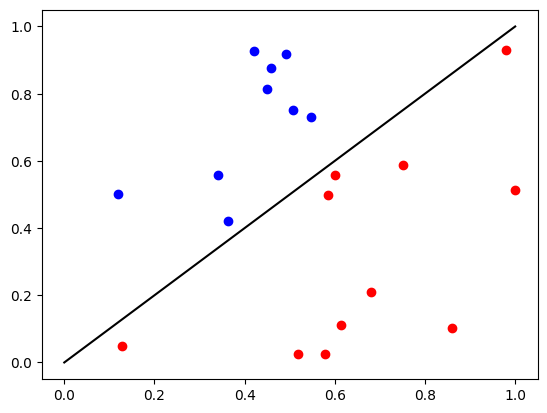

In [3]:
# Generate data
number_of_points = 20
maximum_overlap = 0.0
minimum_spacing = 0.0
[X,Y] = data_generation(number_of_points,maximum_overlap,minimum_spacing, seed=2026)

# Plot the data and the line y = x
plt.plot([x[0] for x in X], [x[1] for x in X], 'ro')
plt.plot([y[0] for y in Y], [y[1] for y in Y], 'bo')
plt.plot([i for i in np.linspace(0,1,100)], [i for i in np.linspace(0,1,100)], 'k-')

# Show the plot
plt.show()

## Linear discrimination main

Set parameter Username
Set parameter LicenseID to value 2751469
Academic license - for non-commercial use only - expires 2026-12-08
Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: 11th Gen Intel(R) Core(TM) i7-1165G7 @ 2.80GHz, instruction set [SSE2|AVX|AVX2|AVX512]
Thread count: 4 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 20 rows, 3 columns and 60 nonzeros (Min)
Model fingerprint: 0x60d1edad
Model has 0 linear objective coefficients
Coefficient statistics:
  Matrix range     [2e-02, 1e+00]
  Objective range  [0e+00, 0e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+00]

Presolve time: 0.00s
Presolved: 20 rows, 3 columns, 60 nonzeros

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0      handle free variables                          0s
       6    0.0000000e+00   0.000000e+00   0.000000e+00      0s

Solved in 6 iterations and 0.00 seconds (0.00 work unit

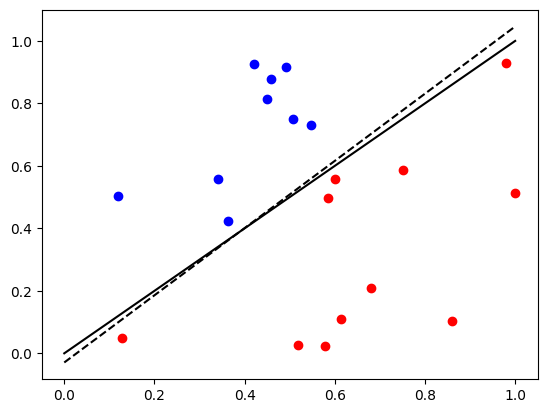

In [4]:
# Initialise model
model = gp.Model()
dimension = 2

# Add variables the line function
a_vector = model.addVars(dimension, name="a", lb = -float('inf'))
b_constant = model.addVar(name="b", lb = -float('inf'))

# Add constraints for X set
for x in X:
    lhs = gp.quicksum(a_vector[i]*x[i] for i in range(dimension)) - b_constant
    model.addConstr(lhs >= 1)

# Add constraints for Y set
for y in Y:
    lhs = gp.quicksum(a_vector[i]*y[i] for i in range(dimension)) - b_constant
    model.addConstr(lhs <= -1)

# Optimize model
model.optimize()

# Only handle if solution is found
if model.status == 2:
    a_optimal = tuple(a_vector[i].X for i in range(dimension))
    b_optimal = b_constant.X
    print(a_optimal)
    print(b_optimal)

    # Convert answer into level set
    def level_set_x_to_y(a,b,x_1):
        return (1/a[1])*(b - a[0]*x_1)

    # Plot the data and the line y = x
    plt.plot([x[0] for x in X], [x[1] for x in X], 'ro')
    plt.plot([y[0] for y in Y], [y[1] for y in Y], 'bo')
    plt.plot([i for i in np.linspace(0,1,100)], [i for i in np.linspace(0,1,100)], 'k-')
    # Plot resulting line
    plt.plot(
        [i for i in np.linspace(0,1,100)],
        [level_set_x_to_y(a_optimal,b_optimal,i) for i in np.linspace(0,1,100)],
        'k--',
        )

    # Show the plot
    plt.show()

## Linear discrimination alternative

In [5]:
# Initialise model
model = gp.Model()
dimension = 2

# Add variables for lambda
lbd = model.addVars(len(X), name="lambda")
lbd_tilde = model.addVars(len(Y), name="lambda_tilde")

# Normalisation constraints
model.addConstr(gp.quicksum(lbd[i] for i in range(len(X))) == 1)
model.addConstr(gp.quicksum(lbd_tilde[i] for i in range(len(Y))) == 1)

# Add summation constraint
for j in range(dimension):
    lhs = gp.LinExpr()
    for x in X:
        lhs.add(gp.quicksum(lbd[i]*X[i][j] for i in range(len(X))))
    rhs = gp.LinExpr()
    for y in Y:
        rhs.add(gp.quicksum(lbd_tilde[i]*Y[i][j] for i in range(len(Y))))
    model.addConstr(lhs == rhs)

# Optimize model
model.optimize()

# Only handle if solution is found
if model.status == 2:
    print("Model feasible -> Not separable")
elif model.status == 3:
    print("Model infeasible -> Separable")
else:
    print("Unexpected Gurobi outcome")

Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: 11th Gen Intel(R) Core(TM) i7-1165G7 @ 2.80GHz, instruction set [SSE2|AVX|AVX2|AVX512]
Thread count: 4 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 4 rows, 20 columns and 60 nonzeros (Min)
Model fingerprint: 0x1a9daeb2
Model has 0 linear objective coefficients
Coefficient statistics:
  Matrix range     [3e-01, 1e+01]
  Objective range  [0e+00, 0e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+00]

Presolve time: 0.00s
Presolved: 4 rows, 20 columns, 60 nonzeros

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    0.0000000e+00   1.472695e+00   0.000000e+00      0s

Solved in 4 iterations and 0.00 seconds (0.00 work units)
Infeasible model
Model infeasible -> Separable


The following code generates new data with a certain gap between the points

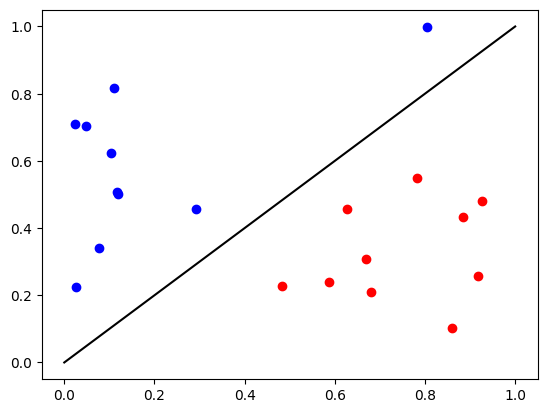

In [6]:
# Generate data
number_of_points = 20
maximum_overlap = 0.0
minimum_spacing = 0.2
[X,Y] = data_generation(number_of_points,maximum_overlap,minimum_spacing, seed=2026)

# Plot the data and the line y = x
plt.plot([x[0] for x in X], [x[1] for x in X], 'ro')
plt.plot([y[0] for y in Y], [y[1] for y in Y], 'bo')
plt.plot([i for i in np.linspace(0,1,100)], [i for i in np.linspace(0,1,100)], 'k-')

# Show the plot
plt.show()

## Robust linear discrimination

Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: 11th Gen Intel(R) Core(TM) i7-1165G7 @ 2.80GHz, instruction set [SSE2|AVX|AVX2|AVX512]
Thread count: 4 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 21 rows, 5 columns and 81 nonzeros (Max)
Model fingerprint: 0x76d9c76c
Model has 1 linear objective coefficients
Model has 1 simple general constraint
  1 NORM
Variable types: 5 continuous, 0 integer (0 binary)
Coefficient statistics:
  Matrix range     [2e-02, 1e+00]
  Objective range  [1e+00, 1e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+00]

Found heuristic solution: objective -0.0000000
Presolve removed 1 rows and 1 columns
Presolve time: 0.00s
Presolved: 20 rows, 4 columns, 68 nonzeros
Presolved model has 1 quadratic constraint(s)
Variable types: 4 continuous, 0 integer (0 binary)
Root relaxation presolve time: 0.02s
Root relaxation presolved: 20 rows, 5 columns, 68 nonzeros
Root 

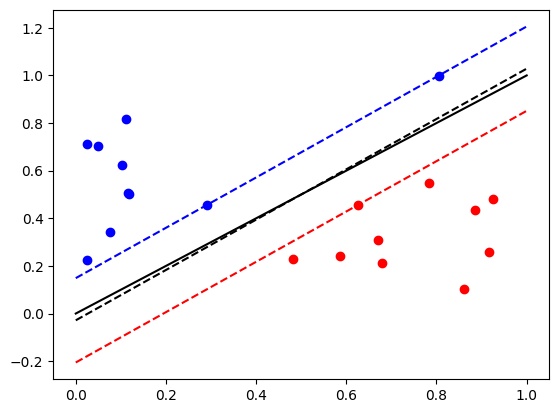

In [7]:
# Initialise model
model = gp.Model()
dimension = 2

# Add variables the line function
a_vector = model.addVars(dimension, name="a", lb = -float('inf'))
b_constant = model.addVar(name="b", lb = -float('inf'))

# Add the value to be maximised
t_value = model.addVar(name="t")

# Add the objective function
model.setObjective(t_value, sense = gp.GRB.MAXIMIZE)

# Add constraints for X set
for x in X:
    lhs = gp.quicksum(a_vector[i]*x[i] for i in range(dimension)) - b_constant
    model.addConstr(lhs >= t_value)

# Add constraints for Y set
for y in Y:
    lhs = gp.quicksum(a_vector[i]*y[i] for i in range(dimension)) - b_constant
    model.addConstr(lhs <= -t_value)

# Ensure the model is bounded
norm_var = model.addVar(name="norm_var")
model.addGenConstrNorm(norm_var, [a_vector[i] for i in a_vector], 2.0)
model.addConstr(norm_var <= 1)

# Optimize model
model.optimize()

# Only handle if solution is found
if model.status == 2:
    a_optimal = tuple(a_vector[i].X for i in range(dimension))
    b_optimal = b_constant.X
    t_optimal = t_value.X
    print("t:", t_optimal)
    print("a:", a_optimal)
    print("b:", b_optimal)

    # Convert answer into level set
    def level_set_x_to_y(a,b,x_1):
        return (1/a[1])*(b - a[0]*x_1)

    # Plot the data and the line y = x
    plt.plot([x[0] for x in X], [x[1] for x in X], 'ro')
    plt.plot([y[0] for y in Y], [y[1] for y in Y], 'bo')
    plt.plot([i for i in np.linspace(0,1,100)], [i for i in np.linspace(0,1,100)], 'k-')
    # Plot resulting line
    plt.plot(
        [i for i in np.linspace(0,1,100)],
        [level_set_x_to_y(a_optimal,b_optimal,i) for i in np.linspace(0,1,100)],
        'k--',
        )
    # Plot resulting boundary lines
    plt.plot(
        [i for i in np.linspace(0,1,100)],
        [level_set_x_to_y(a_optimal,b_optimal+t_optimal,i) for i in np.linspace(0,1,100)],
        'r--',
        )
    plt.plot(
        [i for i in np.linspace(0,1,100)],
        [level_set_x_to_y(a_optimal,b_optimal-t_optimal,i) for i in np.linspace(0,1,100)],
        'b--',
        )

    # Show the plot
    plt.show()

The following code generates new data with overlap

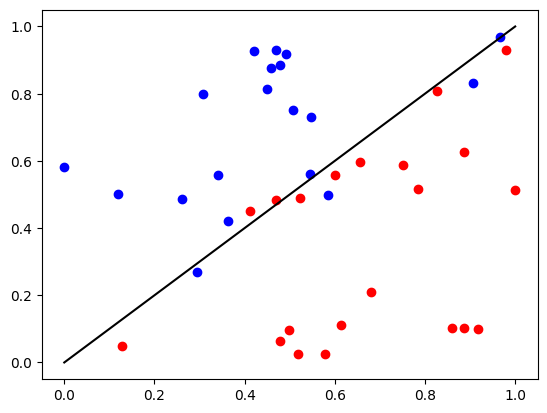

In [8]:
# Generate data
number_of_points = 40
maximum_overlap = 0.2
minimum_spacing = 0.0
[X,Y] = data_generation(number_of_points,maximum_overlap,minimum_spacing, seed=2026)

# Plot the data and the line y = x
plt.plot([x[0] for x in X], [x[1] for x in X], 'ro')
plt.plot([y[0] for y in Y], [y[1] for y in Y], 'bo')
plt.plot([i for i in np.linspace(0,1,100)], [i for i in np.linspace(0,1,100)], 'k-')

# Show the plot
plt.show()

## Support vector classifier

Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: 11th Gen Intel(R) Core(TM) i7-1165G7 @ 2.80GHz, instruction set [SSE2|AVX|AVX2|AVX512]
Thread count: 4 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 40 rows, 44 columns and 160 nonzeros (Min)
Model fingerprint: 0xd21b9dff
Model has 41 linear objective coefficients
Model has 1 simple general constraint
  1 NORM
Variable types: 44 continuous, 0 integer (0 binary)
Coefficient statistics:
  Matrix range     [2e-04, 1e+00]
  Objective range  [1e-01, 1e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+00]

Presolve time: 0.00s
Presolved: 40 rows, 44 columns, 160 nonzeros
Presolved model has 1 quadratic constraint(s)
Variable types: 44 continuous, 0 integer (0 binary)
Root relaxation presolve time: 0.01s
Root relaxation presolved: 40 rows, 44 columns, 160 nonzeros
Root relaxation presolved model has 1 second-order cone constraint
Root barrier l

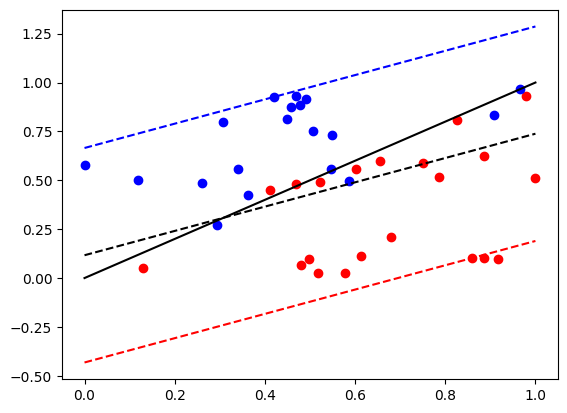

In [10]:
# Initialise model
model = gp.Model()
dimension = 2
gamma = 0.15

# Add variables the line function
a_vector = model.addVars(dimension, name="a", lb = -float('inf'))
b_constant = model.addVar(name="b", lb = -float('inf'))

# Add the u and v values
u_value = model.addVars(len(X), name="u")
v_value = model.addVars(len(Y), name="v")

# Balance with the two-norm
norm_var = model.addVar(name="norm_var")

# Add the objective function
model.setObjective(norm_var + gamma*(u_value.sum() + v_value.sum()), sense = gp.GRB.MINIMIZE)

# Add constraints for X set
for j,x in enumerate(X):
    lhs = gp.quicksum(a_vector[i]*x[i] for i in range(dimension)) - b_constant
    model.addConstr(lhs >= 1 - u_value[j])

# Add constraints for Y set
for j,y in enumerate(Y):
    lhs = gp.quicksum(a_vector[i]*y[i] for i in range(dimension)) - b_constant
    model.addConstr(lhs <= v_value[j] - 1)

# Add the norm variable
model.addGenConstrNorm(norm_var, [a_vector[i] for i in a_vector], 2.0)

# Optimize model
model.optimize()

# Only handle if solution is found
if model.status == 2:
    a_optimal = tuple(a_vector[i].X for i in range(dimension))
    b_optimal = b_constant.X
    print("a:", a_optimal)
    print("b:", b_optimal)
    if sum([value**2 for value in a_optimal]) <= 0.0001:
        print(f"a vector has norm of zero, level set is a line at y = {b_optimal}")
    else:
        # Convert answer into level set
        def level_set_x_to_y(a,b,x_1):
            return (1/a[1])*(b - a[0]*x_1)

        # Plot the data and the line y = x
        plt.plot([x[0] for x in X], [x[1] for x in X], 'ro')
        plt.plot([y[0] for y in Y], [y[1] for y in Y], 'bo')
        plt.plot([i for i in np.linspace(0,1,100)], [i for i in np.linspace(0,1,100)], 'k-')
        # Plot resulting line
        plt.plot(
            [i for i in np.linspace(0,1,100)],
            [level_set_x_to_y(a_optimal,b_optimal,i) for i in np.linspace(0,1,100)],
            'k--',
            )
        # # Plot slab for f=-1 and f=1
        plt.plot(
            [i for i in np.linspace(0,1,100)],
            [level_set_x_to_y(a_optimal,b_optimal+1,i) for i in np.linspace(0,1,100)],
            'r--',
            )
        plt.plot(
            [i for i in np.linspace(0,1,100)],
            [level_set_x_to_y(a_optimal,b_optimal-1,i) for i in np.linspace(0,1,100)],
            'b--',
            )

        # Show the plot
        plt.show()